# Water flow, concentration and cell volume

How can concentration change when none of the trapped solute leaves?

Fall 2024.


# Water, concentration and volume
Predict the direction of water flow for external concentrations 150, 300, 450 mM, starting with 300 fmol inside 1 pL. State the membrane and pressure assumptions before running.

{'150': {'equilibrium_pl': 2.0, 'final_volume_pl': 1.9933832406523782, 'initial_flow_pl_per_s': 0.3}, '300': {'equilibrium_pl': 1.0, 'final_volume_pl': 1.0, 'initial_flow_pl_per_s': 0.0}, '450': {'equilibrium_pl': 0.6666666666666666, 'final_volume_pl': 0.6666666666666674, 'initial_flow_pl_per_s': -0.3}}


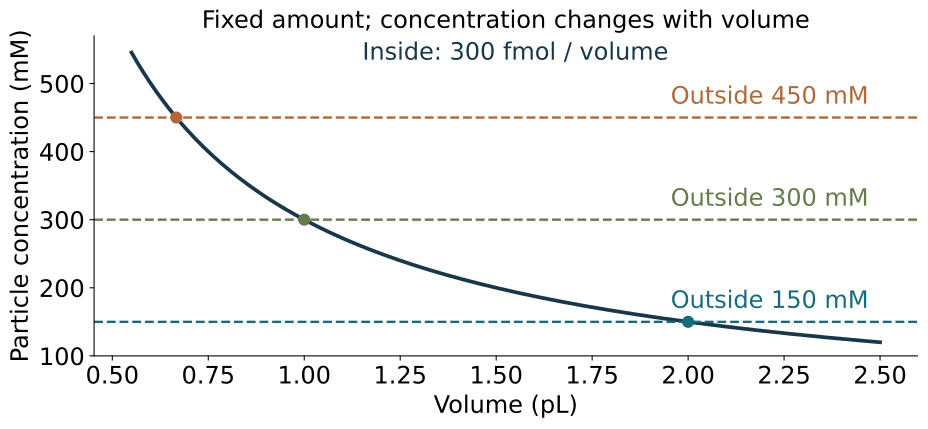

In [1]:
from demo import run, simulate
import numpy as np
from IPython.display import SVG, display
results = run()
print(results['scenarios'])
display(SVG(filename='osmotic-balance.svg'))

Interpret: the intersections give equilibria under the ideal assumptions. Conductance is positive and affects the speed, while the trapped amount and outside concentration determine these endpoints.

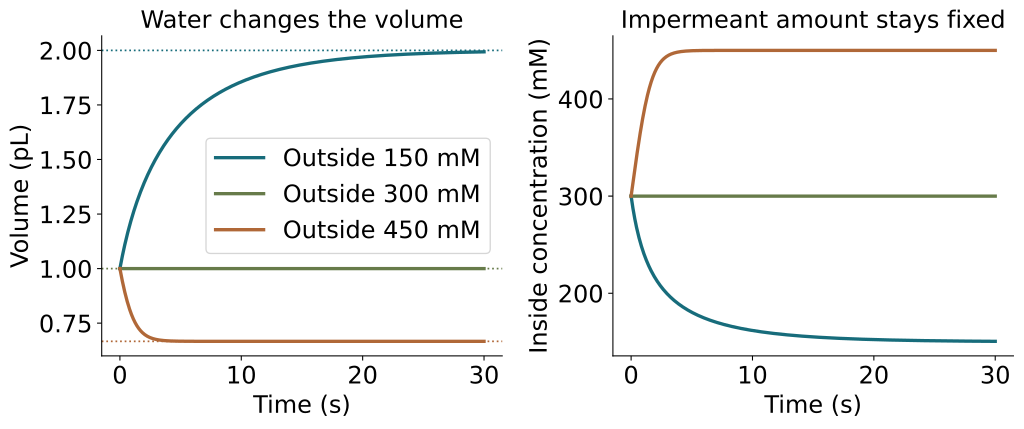

Maximum amount discrepancy: 5.684341886080802e-14


In [2]:
display(SVG(filename='volume-trajectories.svg'))
time, volume = simulate()
inside = 300/volume
assert np.allclose(volume*inside, 300)
print('Maximum amount discrepancy:', np.max(abs(volume*inside-300)))

Modify: change the outside concentration to 200 mM. Predict the direction and equilibrium first. Compare endpoint values at the same time using two step sizes, then explain what this numerical comparison can and cannot establish.

In [3]:
for h in [.1, .05]:
    t, v = simulate(outside_mm=200, step_s=h)
    print('step', h, 'final volume', v[-1], 'equilibrium', 300/200)
_, blocked = simulate(conductance=0)
assert np.all(blocked == 1)
print('Zero conductance keeps initial volume:', np.all(blocked == 1))

step 0.1 final volume 1.499893267724569 equilibrium 1.5
step 0.05 final volume 1.4998866717199193 equilibrium 1.5
Zero conductance keeps initial volume: True


Conclude: identify one mechanism that this model cannot test, such as ion transport or rupture, and name a corresponding observation. All parameters and trajectories are synthetic; the code does not predict viability.